In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, RocCurveDisplay,
    ConfusionMatrixDisplay,
)

In [5]:
df = pd.read_csv('/content/drive/MyDrive/MachineLearning/Praktikum04/Data/calonpembelimobil.csv', sep =',')

df.head()

,ID,Usia,Status,Kelamin,Memiliki_Mobil,Penghasilan,Beli_Mobil
0,1,32,1,0,0,240,1
1,2,49,2,1,1,100,0
2,3,52,1,0,2,250,1
3,4,26,2,1,1,130,0
4,5,45,3,0,2,237,1


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   ID              1000 non-null   int64
 1   Usia            1000 non-null   int64
 2   Status          1000 non-null   int64
 3   Kelamin         1000 non-null   int64
 4   Memiliki_Mobil  1000 non-null   int64
 5   Penghasilan     1000 non-null   int64
 6   Beli_Mobil      1000 non-null   int64
dtypes: int64(7)
memory usage: 54.8 KB


In [3]:
df.isnull().sum()

,0
ID,0
Usia,0
Status,0
Kelamin,0
Memiliki_Mobil,0
Penghasilan,0
Beli_Mobil,0


In [6]:
df.describe()

,ID,Usia,Status,Kelamin,Memiliki_Mobil,Penghasilan,Beli_Mobil
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.00000,1000.000000
mean,500.500000,43.532000,1.469000,0.481000,0.95200,270.09000,0.633000
std,288.819436,12.672078,1.073402,0.499889,0.80146,95.23681,0.482228
min,1.000000,24.000000,0.000000,0.000000,0.00000,95.00000,0.000000
25%,250.750000,33.000000,1.000000,0.000000,0.00000,187.00000,0.000000
50%,500.500000,43.000000,1.000000,0.000000,1.00000,258.50000,1.000000
75%,750.250000,53.000000,2.000000,1.000000,2.00000,352.25000,1.000000
max,1000.000000,164.000000,3.000000,1.000000,4.00000,490.00000,1.000000


In [7]:
feature_columns = ['Usia', 'Status', 'Kelamin', 'Memiliki_Mobil', 'Penghasilan']

X = df[feature_columns]
y = df['Beli_Mobil']

# Pembagian data training dan testing (rasio 80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Jumlah Data Latih (Train): {X_train.shape[0]}")
print(f"Jumlah Data Uji (Test): {X_test.shape[0]}")

Jumlah Data Latih (Train): 800
Jumlah Data Uji (Test): 200


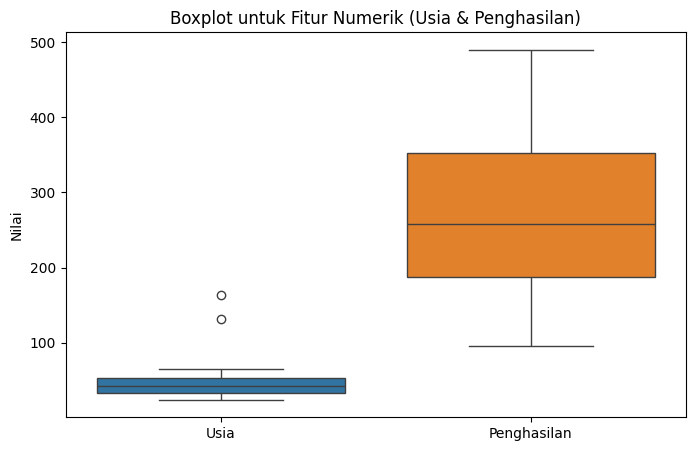

In [29]:
numeric_cols = ['Usia', 'Penghasilan']

plt.figure(figsize=(8, 5))
sns.boxplot(data=df[numeric_cols])
plt.title('Boxplot untuk Fitur Numerik (Usia & Penghasilan)')
plt.ylabel('Nilai')
plt.show()

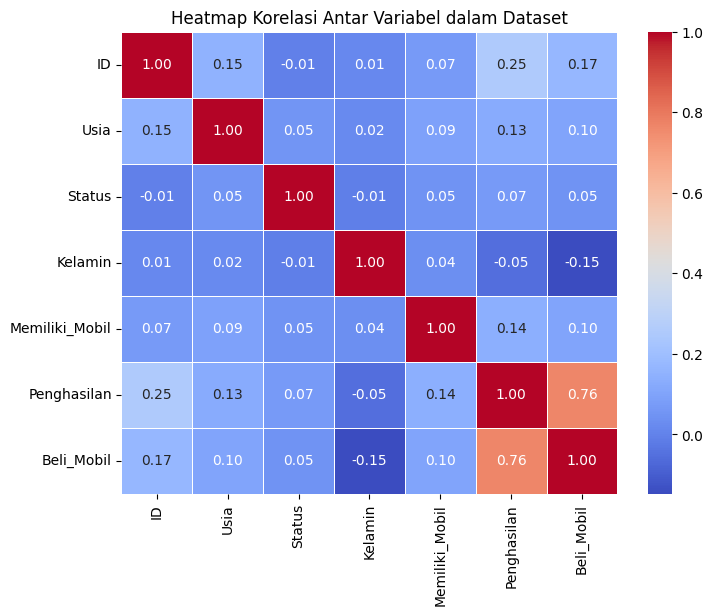

In [30]:
corr_matrix = df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Heatmap Korelasi Antar Variabel dalam Dataset", fontsize=12)
plt.show()

# Membangun Model

In [8]:
# Preprocessor untuk standarisasi seluruh fitur numerik/kolom masukan
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), feature_columns)
    ]
)

# Pipeline menggunakan Logistic Regression
clf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(class_weight='balanced', random_state=42))
])

# Melatih model
clf.fit(X_train, y_train)
print("Model Logistic Regression berhasil dilatih!")

Model Logistic Regression berhasil dilatih!


In [15]:
y_pred = clf.predict(X_test)
y_prob = clf.predict_proba(X_test)[:, 1]

print("=== HASIL EVALUASI MODEL ===")
print(f"Akurasi    : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision  : {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall     : {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-Score   : {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC    : {roc_auc_score(y_test, y_prob):.4f}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))



=== HASIL EVALUASI MODEL ===
Akurasi    : 0.9300
Precision  : 0.9829
Recall     : 0.9055
F1-Score   : 0.9426
ROC-AUC    : 0.9768

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.97      0.91        73
           1       0.98      0.91      0.94       127

    accuracy                           0.93       200
   macro avg       0.92      0.94      0.93       200
weighted avg       0.94      0.93      0.93       200



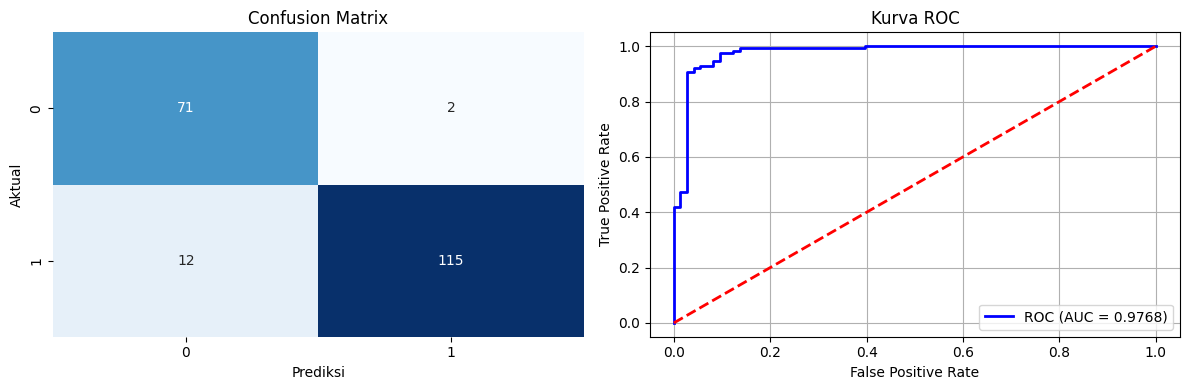

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 1. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0])
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

# 2. Kurva ROC
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, color='blue', lw=2, label=f'ROC (AUC = {roc_auc_score(y_test, y_prob):.4f})')
axes[1].plot([0, 1], [0, 1], color='red', linestyle='--', lw=2)
axes[1].set_title('Kurva ROC')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [17]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=['Tidak Beli (0)', 'Beli (1)']))

                precision    recall  f1-score   support

Tidak Beli (0)       0.86      0.97      0.91        73
      Beli (1)       0.98      0.91      0.94       127

      accuracy                           0.93       200
     macro avg       0.92      0.94      0.93       200
  weighted avg       0.94      0.93      0.93       200



In [31]:
scores = cross_val_score(clf, X, y, cv=5)

# Tampilkan hasil
print("Skor tiap fold:", scores)
print("Rata-rata akurasi:", np.mean(scores))
print("Standar deviasi:", np.std(scores))

Skor tiap fold: [0.78  0.925 0.955 0.945 0.94 ]
Rata-rata akurasi: 0.909
Standar deviasi: 0.06522269543648128


In [26]:
# Ekstraksi nama fitur, koefisien, dan Odds Ratio menggunakan model_pipeline (clf)
feat_names = feature_columns
coefs = clf.named_steps['classifier'].coef_[0]
odds = np.exp(coefs)

# Membuat DataFrame untuk visualisasi ringkas
coef_df = pd.DataFrame({
    'Fitur': feat_names,
    'Koefisien (log-odds)': coefs,
    'Odds Ratio (e^coef)': odds
}).sort_values('Odds Ratio (e^coef)', ascending=False)

# Menampilkan hasil
display(coef_df)

,Fitur,Koefisien (log-odds),Odds Ratio (e^coef)
4,Penghasilan,4.568333,96.383273
3,Memiliki_Mobil,0.078968,1.082169
0,Usia,-0.045073,0.955928
1,Status,-0.132093,0.876259
2,Kelamin,-0.596863,0.550536


In [28]:
# Contoh data baru calon pembeli mobil
data_baru = pd.DataFrame({
    'Usia': [30, 45],
    'Status': [1, 2],         # 1=Menikah, 2=Lajang/Lainnya
    'Kelamin': [0, 1],        # 0=Wanita, 1=Pria
    'Memiliki_Mobil': [0, 2],
    'Penghasilan': [150, 350]
})

pred = clf.predict(data_baru)
prob = clf.predict_proba(data_baru)[:,1]

hasil = data_baru.copy()
hasil['Prob_Beli'] = prob
hasil['Pred (0=Tidak, 1=Ya)'] = pred
display(hasil)

,Usia,Status,Kelamin,Memiliki_Mobil,Penghasilan,Prob_Beli,"Pred (0=Tidak, 1=Ya)"
0,30,1,0,0,150,0.034609,0
1,45,2,1,2,350,0.994231,1
